ติดตั้ง Library

In [5]:
!pip install ultralytics

ตรวจจับวัตถุด้วย YOLOv11


image 1/1 /content/01.jpg: 640x480 (no detections), 9.6ms
Speed: 0.9ms preprocess, 9.6ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 480)


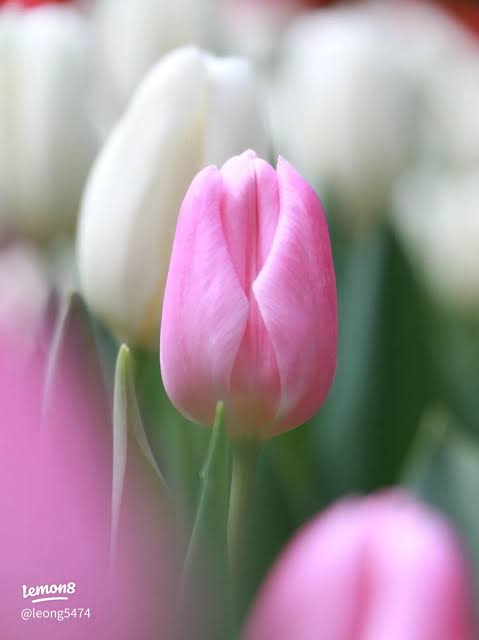

In [6]:
from ultralytics import YOLO
#ดาวน์โหลด Model
model =YOLO('yolo11n.pt')  # Model yolo11n.pt หรือ yolov8n.pt หรือใช้ model ของเราได้

results =model('01.jpg')
results[0].show()

การขอสิทธิ์เข้าถึงข้อมูลใน Google Drive

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


การฝึกโมเดล (Train Model)

In [8]:
from ultralytics import YOLO

# Load a model
model = YOLO("yolo11n.pt")

# Train the model
model.train(
    data="/content/drive/MyDrive/Flower_project/Flower_project/Flower_pro.v3i.yolov11/data.yaml",  # path to dataset YAML
    epochs=10,  # number of training epochs
    imgsz=640,  # image size for training
    batch=16,  # batch size
    lr0=0.001,  # initial learning rate
    device="0"  # device to train on 0 (GPU) หรือ cpu
)


# ประเมินโมเดล (Evaluate model performance on the validation set)
metrics = model.val()


# บันทึกโมเดลที่ฝึกเสร็จแล้ว
model.save('best.pt')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Flower_project/Flower_project/Flower_pro.v3i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tr

## นำภาพขึ้นไปทดสอบบน google colab

โดยใช้โมเดลที่ฝึกแล้ว ชื่อ best.pt

พบวัตถุที่ไม่ทราบสายพันธุ์


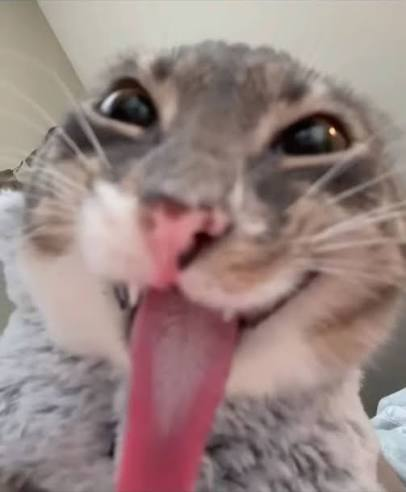

In [9]:
from ultralytics import YOLO
from PIL import Image

model = YOLO('best.pt')
results = model('010.jpg', verbose=False)

if len(results[0].boxes) > 0:
    print("พบดอกไม้ในระบบ!")
    results[0].show()
else:
    print("พบวัตถุที่ไม่ทราบสายพันธุ์")
    display(Image.open('010.jpg'))